# Optimización de hiperparámetros de la CNN para la predicción de RUL en FD001

El proceso es:

1. Cargar los motores de **validación** que se separaron en el EDA (`EDA.ipynb`)
2. Buscar con Optuna la combinación de hiperparámetros con menor RMSE en validación
3. Reentrenar la mejor configuración con todos los datos de entrenamiento y varias semillas
4. Evaluar **una sola vez** en test y comparar con el baseline y con la LSTM optimizada

## 1. Librerías y configuración

In [ ]:
import json
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

c:\Users\Varix\Desktop\TFM_Experimentacion\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
DATA_DIR = Path("data/CMaps/training")
RESULTS_DIR = Path("results/cnn_optuna")
BASELINE_RESULTS = Path("results/cnn_baseline/results.json")
LSTM_OPTUNA_RESULTS = Path("results/lstm_optuna/results.json")

SEED = 42

WINDOW_SIZE = 30
RUL_CAP = 125

# Búsqueda
N_TRIALS = 50
MAX_EPOCHS = 100
PATIENCE = 15

FINAL_SEEDS = [0, 1]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Con convoluciones en GPU, cuDNN puede elegir algoritmos no deterministas
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

## 2. Carga de datos

In [4]:
train_df = pd.read_csv(DATA_DIR / "fd001_train.csv")
val_df = pd.read_csv(DATA_DIR / "fd001_val.csv")
test_df = pd.read_csv(DATA_DIR / "fd001_test.csv")

feature_cols = [
    col for col in train_df.columns if col not in ["engine_id", "time_in_cycles", "RUL"]
]

train_df["RUL"] = train_df["RUL"].clip(upper=RUL_CAP)
val_df["RUL"] = val_df["RUL"].clip(upper=RUL_CAP)
test_df["RUL"] = test_df["RUL"].clip(upper=RUL_CAP)

print(f"Train: {train_df.shape} | Validación: {val_df.shape} | Test: {test_df.shape}")
print(f"Variables ({len(feature_cols)}): {feature_cols}")

Train: (16561, 16) | Validación: (4070, 16) | Test: (13096, 16)
Variables (13): ['T24', 'T30', 'T50', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'BPR', 'htBleed', 'W31', 'W32']


## 3. Separación de validación

In [5]:
fit_df = train_df
val_engines = sorted(val_df["engine_id"].unique().tolist())

# Comprobación de que ningún motor está a la vez en entrenamiento y validación
assert not set(val_engines) & set(fit_df["engine_id"].unique())

print(f"Motores de entrenamiento: {fit_df['engine_id'].nunique()}")
print(f"Motores de validación:    {len(val_engines)} -> {val_engines}")

Motores de entrenamiento: 80
Motores de validación:    20 -> [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


## 4. Ventanas temporales

In [6]:
def create_train_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        features = engine_data[feature_cols].to_numpy()
        rul = engine_data["RUL"].to_numpy()
        for end in range(window_size, len(engine_data) + 1):
            windows.append(features[end - window_size : end])
            targets.append(rul[end - 1])
    return np.array(windows), np.array(targets)


def create_test_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        windows.append(engine_data[feature_cols].to_numpy()[-window_size:])
        targets.append(engine_data["RUL"].iloc[-1])
    return np.array(windows), np.array(targets)


X_fit, y_fit = create_train_windows(fit_df, feature_cols, WINDOW_SIZE)
X_val, y_val = create_train_windows(val_df, feature_cols, WINDOW_SIZE)
X_full, y_full = create_train_windows(
    pd.concat([fit_df, val_df]), feature_cols, WINDOW_SIZE
)
X_test, y_test = create_test_windows(test_df, feature_cols, WINDOW_SIZE)

print(f"X_fit:  {X_fit.shape}  (entrenamiento durante la búsqueda)")
print(f"X_val:  {X_val.shape}   (validación durante la búsqueda)")
print(f"X_full: {X_full.shape}  (entrenamiento final: fit + val)")
print(f"X_test: {X_test.shape}")

X_fit:  (14241, 30, 13)  (entrenamiento durante la búsqueda)
X_val:  (3490, 30, 13)   (validación durante la búsqueda)
X_full: (17731, 30, 13)  (entrenamiento final: fit + val)
X_test: (100, 30, 13)


## 5. Modelo CNN

In [7]:
class CNNModel(nn.Module):
    def __init__(
        self, n_features, window_size, n_filters, kernel_size, num_conv_layers, dropout
    ):
        super().__init__()
        layers = []
        in_channels = n_features
        for _ in range(num_conv_layers):
            layers += [
                nn.Conv1d(in_channels, n_filters, kernel_size, padding="same"),
                nn.ReLU(),
            ]
            in_channels = n_filters
        self.conv = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(n_filters * window_size, 1)

    def forward(self, x):
        # (lote, ciclos, variables) -> (lote, variables, ciclos)
        x = x.permute(0, 2, 1)
        x = self.conv(x)
        x = x.flatten(start_dim=1)
        return self.output_layer(self.dropout(x)).squeeze(-1)


def build_model(params):
    return CNNModel(
        n_features=len(feature_cols),
        window_size=WINDOW_SIZE,
        n_filters=params["n_filters"],
        kernel_size=params["kernel_size"],
        num_conv_layers=params["num_conv_layers"],
        dropout=params["dropout"],
    )

## 6. Funciones de entrenamiento y evaluación

In [8]:
def make_loader(X, y, batch_size):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        # Objetivo escalado a [0, 1]
        torch.tensor(y / RUL_CAP, dtype=torch.float32),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()


def predict(model, X):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        # Se desescala para devolver el RUL en ciclos
        return model(X_tensor).cpu().numpy() * RUL_CAP


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))


def phm08_score(y_true, y_pred):
    errors = y_pred - y_true
    penalties = np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    return np.sum(penalties)

## 7. Búsqueda de hiperparámetros con Optuna

Espacio de búsqueda:

| Hiperparámetro | Valores |
|---|---|
| `n_filters` | 16, 32, 64, 128 |
| `kernel_size` | 3, 5, 7, 9 |
| `num_conv_layers` | 1, 2, 3, 4 |
| `dropout` | entre 0.0 y 0.5 |
| `learning_rate` | entre 0.0001 y 0.01 (escala logarítmica) |
| `batch_size` | 32, 64, 128, 256 |

Cada trial:

1. Entrena una CNN con los hiperparámetros propuestos
2. Al final de cada época calcula el RMSE en validación
3. Se para si pasan `PATIENCE` épocas sin mejorar (*early stopping*)
4. Devuelve el mejor RMSE de validación y guarda en qué época se alcanzó

In [9]:
def objective(trial):
    params = {
        "n_filters": trial.suggest_categorical("n_filters", [16, 32, 64, 128]),
        "kernel_size": trial.suggest_categorical("kernel_size", [3, 5, 7, 9]),
        "num_conv_layers": trial.suggest_int("num_conv_layers", 1, 4),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
    }

    set_seed(SEED)
    model = build_model(params).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    criterion = nn.MSELoss()
    loader = make_loader(X_fit, y_fit, params["batch_size"])

    best_val_rmse = float("inf")
    best_epoch = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_one_epoch(model, loader, optimizer, criterion)
        val_rmse = rmse(y_val, predict(model, X_val))

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_epoch = epoch

        # Poda: Optuna decide si este trial va peor que los anteriores
        trial.report(val_rmse, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

        # Early stopping
        if epoch - best_epoch >= PATIENCE:
            break

    trial.set_user_attr("best_epoch", best_epoch)
    return best_val_rmse

In [10]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=15),
)
study.optimize(objective, n_trials=N_TRIALS)

[I 2026-09-27 19:19:44,921] A new study created in memory with name: no-name-69652079-962b-4405-97d8-6a732f32ec39
[I 2026-09-27 19:21:14,261] Trial 0 finished with value: 12.055212690268034 and parameters: {'n_filters': 32, 'kernel_size': 9, 'num_conv_layers': 3, 'dropout': 0.35403628889802274, 'learning_rate': 0.00010994335574766199, 'batch_size': 32}. Best is trial 0 with value: 12.055212690268034.
[I 2026-09-27 19:21:32,789] Trial 1 finished with value: 12.50149168092657 and parameters: {'n_filters': 64, 'kernel_size': 5, 'num_conv_layers': 2, 'dropout': 0.22803499210851796, 'learning_rate': 0.0037183641805732083, 'batch_size': 128}. Best is trial 0 with value: 12.055212690268034.
[I 2026-09-27 19:21:47,607] Trial 2 finished with value: 12.145041729040068 and parameters: {'n_filters': 128, 'kernel_size': 3, 'num_conv_layers': 3, 'dropout': 0.22007624686980065, 'learning_rate': 0.00017541893487450815, 'batch_size': 128}. Best is trial 0 with value: 12.055212690268034.
[I 2026-09-27 1

## 8. Resultados de la búsqueda

In [11]:
best_params = study.best_params
best_epoch = study.best_trial.user_attrs["best_epoch"]

n_complete = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
n_pruned = len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])

print(f"Trials completados: {n_complete} | Trials podados: {n_pruned}")
print(f"Mejor trial: #{study.best_trial.number}")
print(f"RMSE validación: {study.best_value:.2f} (época {best_epoch})")
print("Mejores hiperparámetros:")
for name, value in best_params.items():
    print(f"  {name:<15}{value}")

Trials completados: 42 | Trials podados: 8
Mejor trial: #49
RMSE validación: 11.75 (época 25)
Mejores hiperparámetros:
  n_filters      32
  kernel_size    9
  num_conv_layers2
  dropout        0.467917937560652
  learning_rate  0.0008496191415723984
  batch_size     64


Los 10 mejores trials:

In [12]:
trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "user_attrs", "state")
)
trials_df = trials_df.rename(
    columns=lambda col: col.replace("params_", "").replace("user_attrs_", "")
)
trials_df = trials_df.rename(columns={"value": "val_rmse"})

trials_df[trials_df["state"] == "COMPLETE"].sort_values("val_rmse").head(10)

,number,val_rmse,batch_size,dropout,kernel_size,learning_rate,n_filters,num_conv_layers,best_epoch,state
49,49,11.752886,64,0.467918,9,0.000850,32,2,25.0,COMPLETE
29,29,11.759480,64,0.465998,9,0.001027,32,2,37.0,COMPLETE
31,31,11.839041,64,0.481380,9,0.000842,32,2,25.0,COMPLETE
34,34,11.878698,64,0.466491,9,0.001092,32,2,23.0,COMPLETE
25,25,11.895979,32,0.327902,9,0.000176,32,2,38.0,COMPLETE
35,35,11.958159,64,0.454910,9,0.001362,32,2,37.0,COMPLETE
24,24,11.958354,32,0.373836,9,0.000188,32,2,31.0,COMPLETE
41,41,11.968536,64,0.491873,9,0.001530,32,2,25.0,COMPLETE
45,45,11.984976,64,0.285805,9,0.001683,32,2,12.0,COMPLETE
39,39,11.987006,64,0.323393,9,0.002042,32,3,15.0,COMPLETE


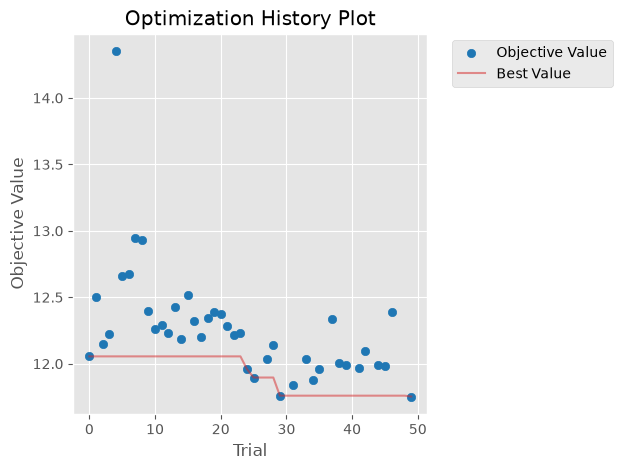

In [13]:
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()

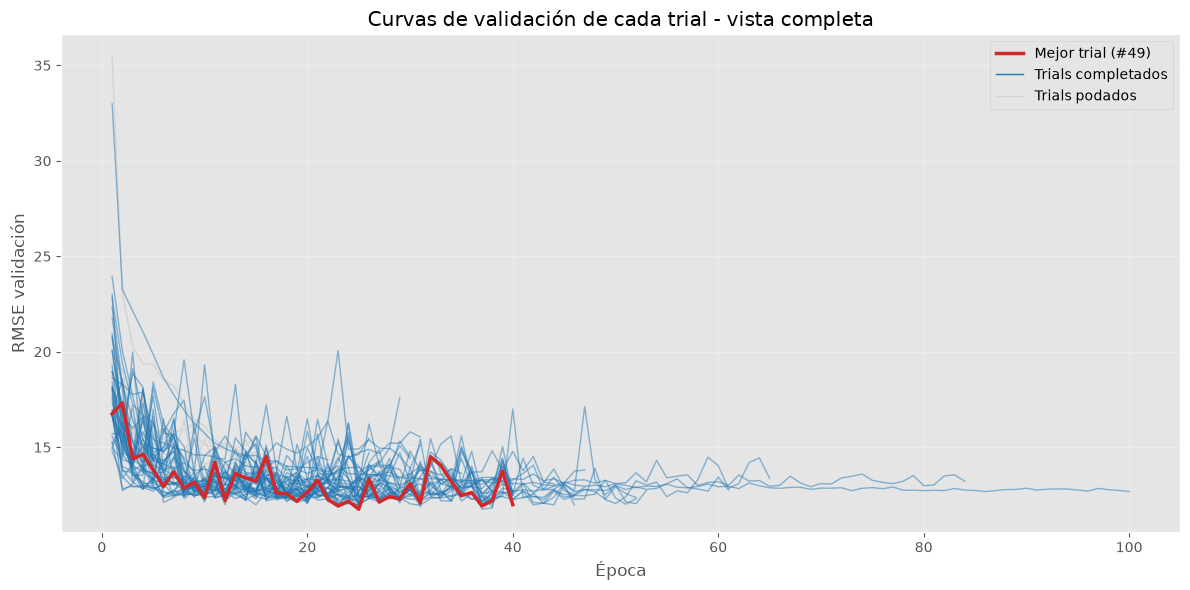

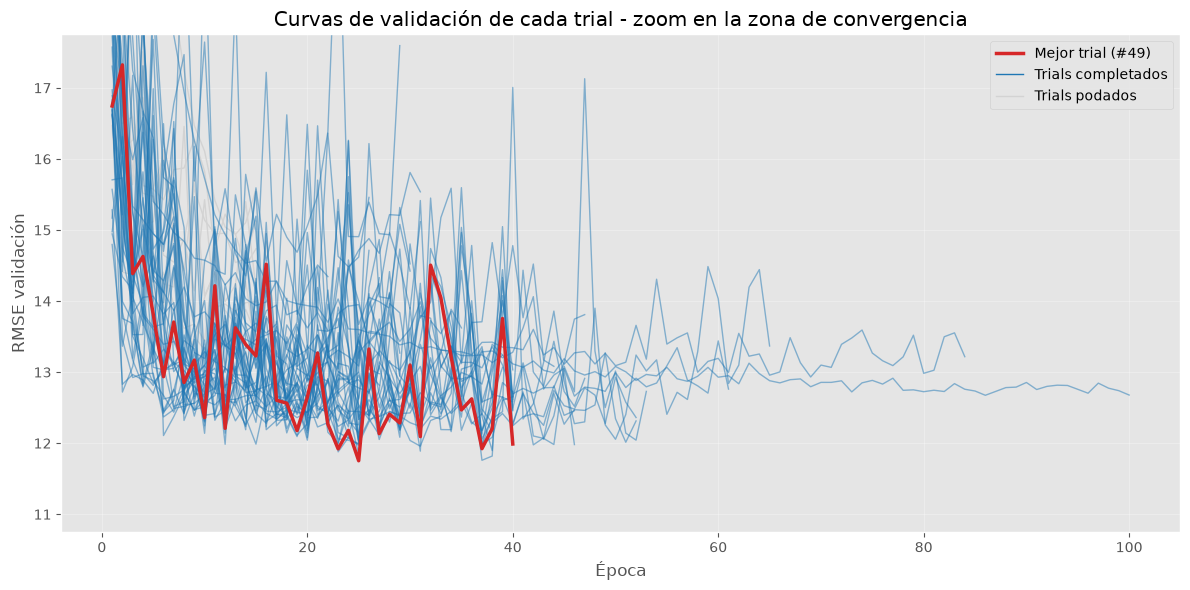

In [14]:
def plot_trial_curves(ax):
    for trial in study.trials:
        # RMSE de validación registrado en cada época con trial.report
        epochs = list(trial.intermediate_values.keys())
        val_rmses = list(trial.intermediate_values.values())

        if trial.number == study.best_trial.number:
            style = {"color": "tab:red", "linewidth": 2.5, "zorder": 3}
        elif trial.state == optuna.trial.TrialState.PRUNED:
            style = {"color": "lightgray", "linewidth": 1, "zorder": 1}
        else:
            style = {"color": "tab:blue", "linewidth": 1, "alpha": 0.5, "zorder": 2}

        ax.plot(epochs, val_rmses, **style)

    # Líneas vacías solo para construir una leyenda con tres entradas
    ax.plot([], [], color="tab:red", linewidth=2.5, label=f"Mejor trial (#{study.best_trial.number})")
    ax.plot([], [], color="tab:blue", linewidth=1, label="Trials completados")
    ax.plot([], [], color="lightgray", linewidth=1, label="Trials podados")

    ax.set_xlabel("Época")
    ax.set_ylabel("RMSE validación")
    ax.grid(alpha=0.3)
    ax.legend()


# Vista completa
fig, ax = plt.subplots(figsize=(12, 6))
plot_trial_curves(ax)
ax.set_title("Curvas de validación de cada trial - vista completa")
plt.tight_layout()
plt.show()

# Zoom en la zona de convergencia
fig, ax = plt.subplots(figsize=(12, 6))
plot_trial_curves(ax)
ax.set_ylim(study.best_value - 1, study.best_value + 6)
ax.set_title("Curvas de validación de cada trial - zoom en la zona de convergencia")
plt.tight_layout()
plt.show()

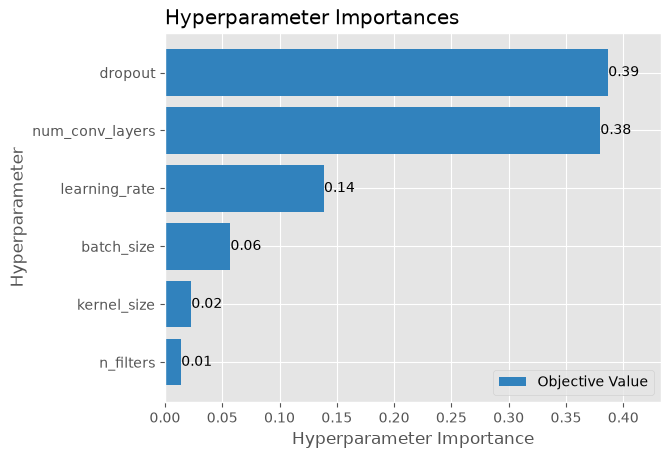

In [15]:
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

## 9. Entrenamiento final y evaluación en test

In [16]:
test_results = []
test_predictions = []

for seed in FINAL_SEEDS:
    set_seed(seed)
    model = build_model(best_params).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=best_params["learning_rate"])
    criterion = nn.MSELoss()
    loader = make_loader(X_full, y_full, best_params["batch_size"])

    for epoch in range(best_epoch):
        train_one_epoch(model, loader, optimizer, criterion)

    y_pred = predict(model, X_test)
    test_predictions.append(y_pred)
    test_results.append(
        {
            "seed": seed,
            "test_rmse": rmse(y_test, y_pred),
            "test_phm08_score": phm08_score(y_test, y_pred),
        }
    )

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), RESULTS_DIR / f"cnn_optuna_seed{seed}.pt")
    print(
        f"Semilla {seed} | RMSE test: {test_results[-1]['test_rmse']:.2f} | Score PHM08: {test_results[-1]['test_phm08_score']:.2f}"
    )

test_results_df = pd.DataFrame(test_results)

Semilla 0 | RMSE test: 16.01 | Score PHM08: 544.58
Semilla 1 | RMSE test: 13.79 | Score PHM08: 278.43


In [17]:
rmse_mean, rmse_std = (
    test_results_df["test_rmse"].mean(),
    test_results_df["test_rmse"].std(),
)
score_mean, score_std = (
    test_results_df["test_phm08_score"].mean(),
    test_results_df["test_phm08_score"].std(),
)

with open(BASELINE_RESULTS) as file:
    baseline_metrics = json.load(file)["metrics"]

rows = [
    (
        "CNN baseline (1 semilla)",
        f"{baseline_metrics['test_rmse']:.2f}",
        f"{baseline_metrics['test_phm08_score']:.2f}",
    ),
    (
        "CNN optimizada",
        f"{rmse_mean:.2f} ± {rmse_std:.2f}",
        f"{score_mean:.2f} ± {score_std:.2f}",
    ),
]

# La LSTM optimizada se incluye si ya se ha ejecutado lstm_optuna.ipynb
if LSTM_OPTUNA_RESULTS.exists():
    with open(LSTM_OPTUNA_RESULTS) as file:
        lstm_metrics = json.load(file)["metrics"]
    rows.append(
        (
            "LSTM optimizada",
            f"{lstm_metrics['test_rmse_mean']:.2f} ± {lstm_metrics['test_rmse_std']:.2f}",
            f"{lstm_metrics['test_phm08_score_mean']:.2f} ± {lstm_metrics['test_phm08_score_std']:.2f}",
        )
    )

print(f"{'':<26}{'RMSE test':>16}{'Score PHM08':>20}")
for name, rmse_text, score_text in rows:
    print(f"{name:<26}{rmse_text:>16}{score_text:>20}")

                                 RMSE test         Score PHM08
CNN baseline (1 semilla)             13.45              293.17
CNN optimizada                14.90 ± 1.57     411.51 ± 188.20
LSTM optimizada               14.45 ± 1.30     444.14 ± 196.59


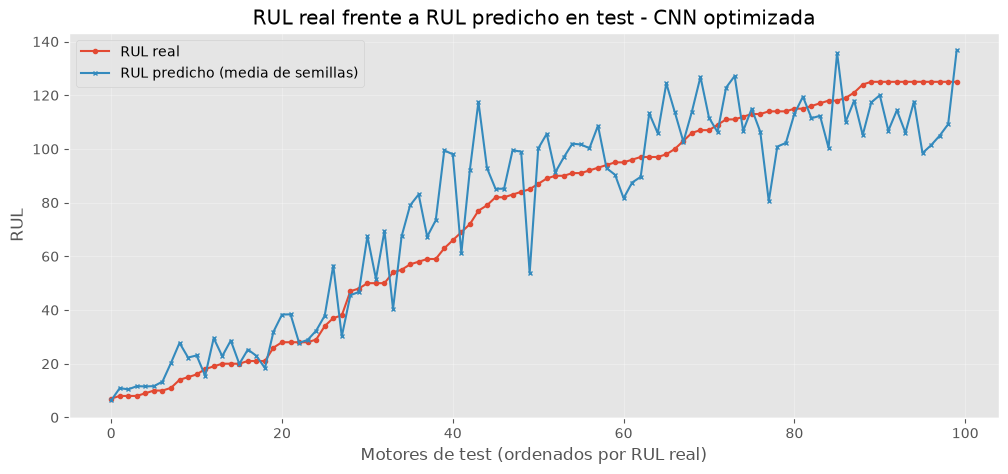

In [18]:
mean_prediction = np.mean(test_predictions, axis=0)
order = np.argsort(y_test)

plt.figure(figsize=(12, 5))
plt.plot(y_test[order], label="RUL real", marker="o", markersize=3)
plt.plot(
    mean_prediction[order],
    label="RUL predicho (media de semillas)",
    marker="x",
    markersize=3,
)
plt.title("RUL real frente a RUL predicho en test - CNN optimizada")
plt.xlabel("Motores de test (ordenados por RUL real)")
plt.ylabel("RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 10. Guardado de resultados

In [19]:
trials_df.to_csv(RESULTS_DIR / "optuna_trials.csv", index=False)

best_model = build_model(best_params)

results = {
    "hyperparameters": {
        **best_params,
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "epochs": best_epoch,
    },
    "search": {
        "n_trials": N_TRIALS,
        "n_complete": n_complete,
        "n_pruned": n_pruned,
        "n_val_engines": len(val_engines),
        "best_val_rmse": float(study.best_value),
    },
    "n_features": len(feature_cols),
    "trainable_parameters": sum(p.numel() for p in best_model.parameters()),
    "metrics": {
        "test_rmse_mean": float(rmse_mean),
        "test_rmse_std": float(rmse_std),
        "test_phm08_score_mean": float(score_mean),
        "test_phm08_score_std": float(score_std),
        "per_seed": [
            {
                "seed": r["seed"],
                "test_rmse": float(r["test_rmse"]),
                "test_phm08_score": float(r["test_phm08_score"]),
            }
            for r in test_results
        ],
    },
}

with open(RESULTS_DIR / "results.json", "w") as file:
    json.dump(results, file, indent=4)

print(json.dumps(results, indent=4))

{
    "hyperparameters": {
        "n_filters": 32,
        "kernel_size": 9,
        "num_conv_layers": 2,
        "dropout": 0.467917937560652,
        "learning_rate": 0.0008496191415723984,
        "batch_size": 64,
        "window_size": 30,
        "rul_cap": 125,
        "epochs": 25
    },
    "search": {
        "n_trials": 50,
        "n_complete": 42,
        "n_pruned": 8,
        "n_val_engines": 20,
        "best_val_rmse": 11.75288642069709
    },
    "n_features": 13,
    "trainable_parameters": 13985,
    "metrics": {
        "test_rmse_mean": 14.900517418583288,
        "test_rmse_std": 1.5719586898332634,
        "test_phm08_score_mean": 411.50702145743855,
        "test_phm08_score_std": 188.19687059018565,
        "per_seed": [
            {
                "seed": 0,
                "test_rmse": 16.01206006790951,
                "test_phm08_score": 544.582304849846
            },
            {
                "seed": 1,
                "test_rmse": 13.78897476925